# Notebook 04g: CatBoost (Categorical Boosting)
**Algorithm:** CatBoost Regressor
**Core Strategy:** Instead of relying on One-Hot Encoding (which explodes our dataset into sparse, noisy columns), CatBoost handles raw text categories natively using Ordered Target Encoding. By keeping the dataset small and dense, we hypothesize that CatBoost can match or beat LightGBM without needing rigorous feature selection.


## 1. Imports & Data Loading


In [1]:
# Uncomment and run this if CatBoost is not installed in your environment:
# !pip install catboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
import os

sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

PROC_DIR = "../../data/processed/"

# Load the CLEAN TEXT dataset (Before One-Hot Encoding)
X_train = pd.read_csv(f"{PROC_DIR}X_train_clean_text.csv")
X_test = pd.read_csv(f"{PROC_DIR}X_test_clean_text.csv")

y_train = pd.read_csv(f"{PROC_DIR}y_train.csv").squeeze()
y_test = pd.read_csv(f"{PROC_DIR}y_test.csv").squeeze()

# CatBoost needs text columns to be strictly strings (no floats/NaNs mixed in)
# We fill missing categorical values with 'Missing' and numeric with 0
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()
num_cols = X_train.select_dtypes(exclude=['object']).columns.tolist()

X_train[cat_cols] = X_train[cat_cols].fillna('Missing')
X_test[cat_cols] = X_test[cat_cols].fillna('Missing')

X_train[num_cols] = X_train[num_cols].fillna(0)
X_test[num_cols] = X_test[num_cols].fillna(0)

print(f"Loaded Clean Text Dataset: {X_train.shape}")
print(f"Number of Categorical Columns detected: {len(cat_cols)}")


Loaded Clean Text Dataset: (958, 75)
Number of Categorical Columns detected: 22


## 2. Baseline CatBoost (Untuned)


> CatBoost is famous for having incredible default hyperparameters. Let's see what it scores directly out of the box.


In [2]:
# Initialize CatBoost (silent=True prevents massive text output)
cb_base = CatBoostRegressor(cat_features=cat_cols, random_state=42, silent=True)
cb_base.fit(X_train, y_train)

y_train_pred_base = cb_base.predict(X_train)
y_test_pred_base = cb_base.predict(X_test)

train_mae_base = mean_absolute_error(y_train, y_train_pred_base)
test_mae_base = mean_absolute_error(y_test, y_test_pred_base)
train_r2_base = r2_score(y_train, y_train_pred_base)
test_r2_base = r2_score(y_test, y_test_pred_base)
within_10_base = (abs(y_test - y_test_pred_base) / y_test <= 0.10).mean() * 100

print("=== BASELINE (UNTUNED) CATBOOST METRICS ===")
print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R² Score':<25} {train_r2_base:>15.4f} {test_r2_base:>15.4f}")
print(f"{'MAE ($)':<25} {train_mae_base:>15,.2f} {test_mae_base:>15,.2f}")
print('-' * 55)
print(f"Predictions within 10%: {within_10_base:.1f}%")
print(f"\nFor context, LightGBM (Tuned) achieved a Test MAE of $15,591.")


=== BASELINE (UNTUNED) CATBOOST METRICS ===
Metric                              Train            Test
-------------------------------------------------------
R² Score                           0.9923          0.9250
MAE ($)                          4,904.06       11,730.36
-------------------------------------------------------
Predictions within 10%: 80.4%

For context, LightGBM (Tuned) achieved a Test MAE of $15,591.


### Visualizing the Baseline


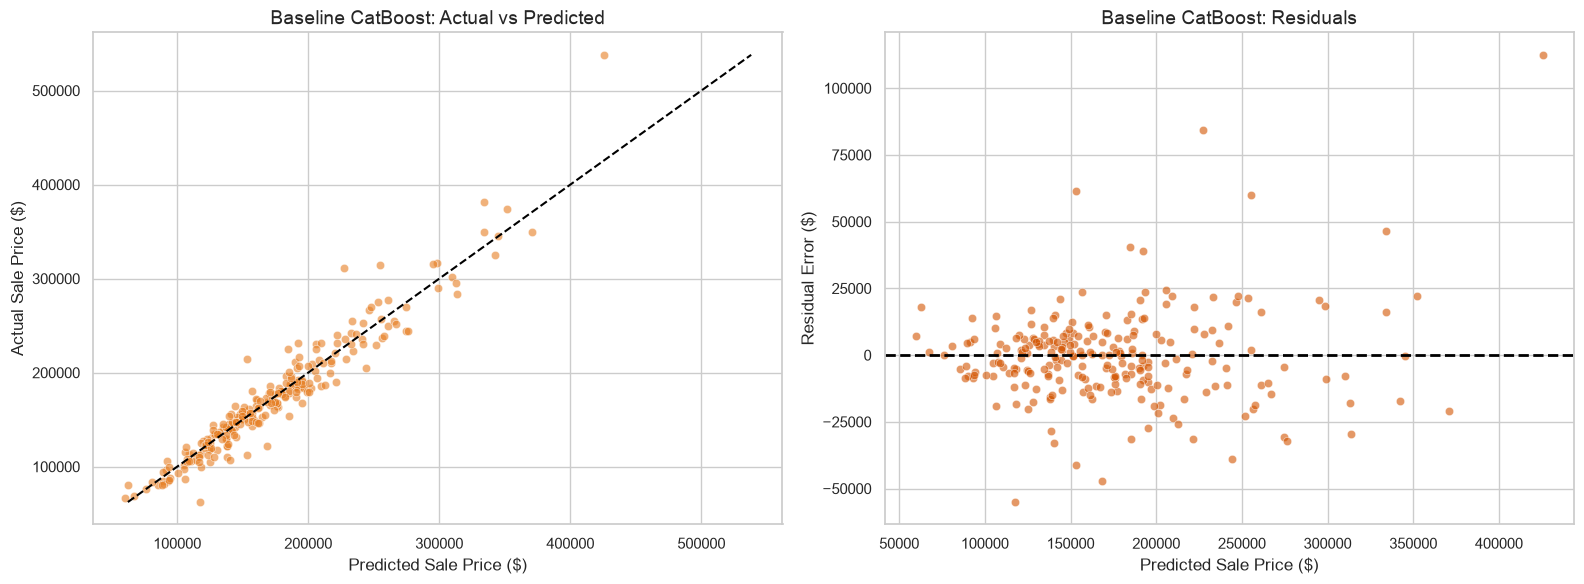

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=y_test_pred_base, y=y_test, alpha=0.6, color="#e67e22", ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="black", linestyle="--")
axes[0].set_title('Baseline CatBoost: Actual vs Predicted', fontsize=14)
axes[0].set_xlabel('Predicted Sale Price ($)')
axes[0].set_ylabel('Actual Sale Price ($)')

residuals_base = y_test - y_test_pred_base
sns.scatterplot(x=y_test_pred_base, y=residuals_base, alpha=0.6, color="#d35400", ax=axes[1])
axes[1].axhline(y=0, color="black", linestyle="--", lw=2)
axes[1].set_title('Baseline CatBoost: Residuals', fontsize=14)
axes[1].set_xlabel('Predicted Sale Price ($)')
axes[1].set_ylabel('Residual Error ($)')

plt.tight_layout()
plt.show()


## 3. Hyperparameter Tuning (GridSearch)


> **Warning:** CatBoost takes longer to tune than LightGBM because of the complex categorical encoding. We will keep the grid slightly smaller.


In [4]:
param_grid = {
    'iterations': [500, 1000],
    'learning_rate': [0.05, 0.1],
    'depth': [4, 6]
}
print("Starting CatBoost Native GridSearch... (This may take a few minutes)")
# We use CatBoost's native grid_search instead of Scikit-Learn to avoid cloning issues with cat_features
cb_tune = CatBoostRegressor(cat_features=cat_cols, random_state=42, silent=True, loss_function='MAE')
# The native grid_search automatically fits the best parameters to the cb_tune object!
grid_search_result = cb_tune.grid_search(param_grid, X=X_train, y=y_train, cv=3, plot=False, verbose=False)
best_cb = cb_tune
print(f"\nOptimal Hyperparameters: {grid_search_result['params']}")


Starting CatBoost Native GridSearch... (This may take a few minutes)

bestTest = 14822.86937
bestIteration = 493


bestTest = 15932.75959
bestIteration = 490


bestTest = 14555.07206
bestIteration = 999


bestTest = 15565.26051
bestIteration = 752


bestTest = 15357.91383
bestIteration = 476


bestTest = 16562.99218
bestIteration = 136


bestTest = 15233.69065
bestIteration = 994


bestTest = 16562.99218
bestIteration = 136

Training on fold [0/3]

bestTest = 12680.63838
bestIteration = 981

Training on fold [1/3]

bestTest = 12982.65602
bestIteration = 971

Training on fold [2/3]

bestTest = 14371.13652
bestIteration = 999


Optimal Hyperparameters: {'depth': 4, 'learning_rate': 0.05, 'iterations': 1000}


## 4. Evaluate Tuned Model


In [5]:
y_train_pred = best_cb.predict(X_train)
y_test_pred = best_cb.predict(X_test)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)
train_rmse = mean_squared_error(y_train, y_train_pred) ** 0.5
test_rmse = mean_squared_error(y_test, y_test_pred) ** 0.5
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

within_10 = (abs(y_test - y_test_pred) / y_test <= 0.10).mean() * 100

print("=== TUNED CATBOOST METRICS ===")
print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R² Score':<25} {train_r2:>15.4f} {test_r2:>15.4f}")
print(f"{'RMSE ($)':<25} {train_rmse:>15,.2f} {test_rmse:>15,.2f}")
print(f"{'MAE ($)':<25} {train_mae:>15,.2f} {test_mae:>15,.2f}")
print('-' * 55)
print(f"Predictions within 10%: {within_10:.1f}%")


=== TUNED CATBOOST METRICS ===
Metric                              Train            Test
-------------------------------------------------------
R² Score                           0.9719          0.9260
RMSE ($)                        11,887.43       17,501.35
MAE ($)                          6,764.04       11,816.56
-------------------------------------------------------
Predictions within 10%: 79.2%


## 5. Diagnostic Plots


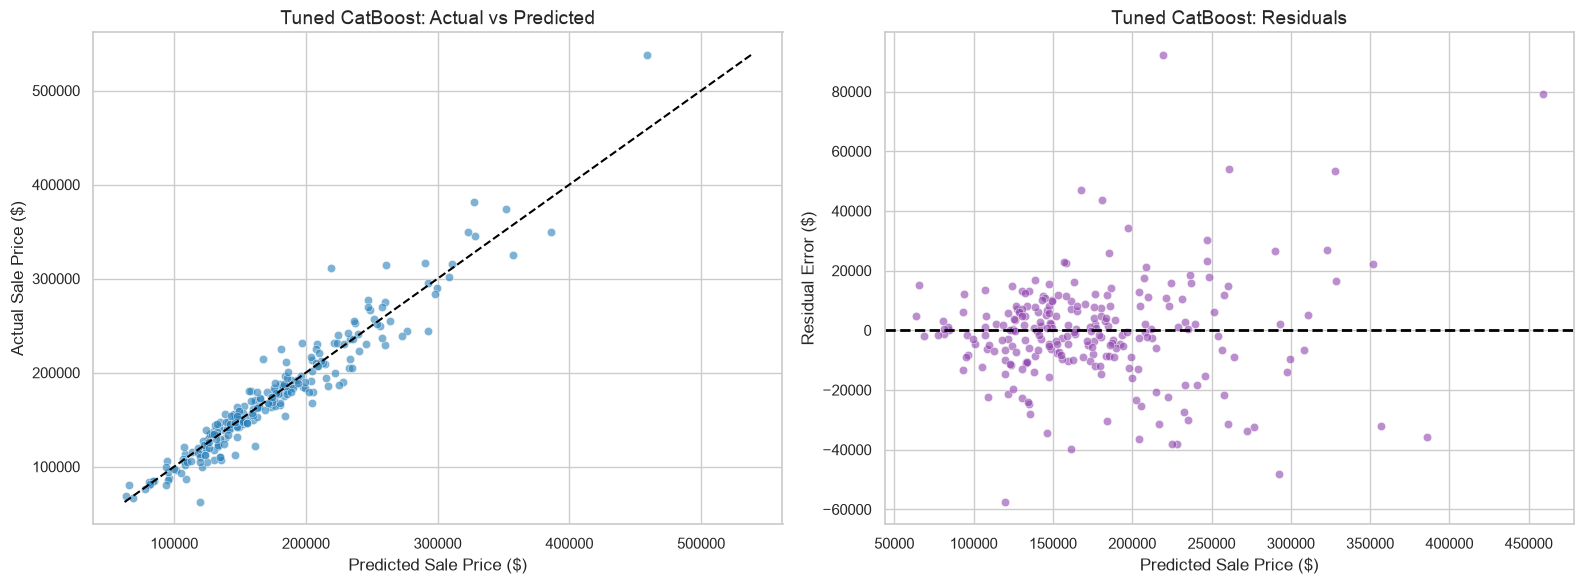

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=y_test_pred, y=y_test, alpha=0.6, color="#2980b9", ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="black", linestyle="--")
axes[0].set_title('Tuned CatBoost: Actual vs Predicted', fontsize=14)
axes[0].set_xlabel('Predicted Sale Price ($)')
axes[0].set_ylabel('Actual Sale Price ($)')

residuals = y_test - y_test_pred
sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.6, color="#8e44ad", ax=axes[1])
axes[1].axhline(y=0, color="black", linestyle="--", lw=2)
axes[1].set_title('Tuned CatBoost: Residuals', fontsize=14)
axes[1].set_xlabel('Predicted Sale Price ($)')
axes[1].set_ylabel('Residual Error ($)')

plt.tight_layout()
plt.show()


## 6. Feature Importance (Dense vs Sparse)


> Notice how dense categorical columns like `Neighborhood` rank much higher than they did when they were shattered into 25 separate columns by One-Hot Encoding!


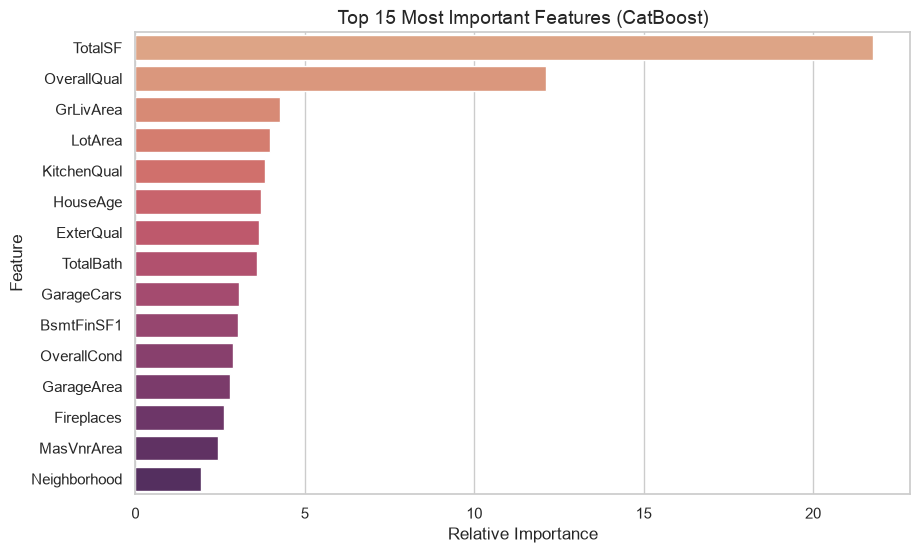

In [7]:
importances = best_cb.get_feature_importance()
feature_names = X_train.columns

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='flare')
plt.title('Top 15 Most Important Features (CatBoost)', fontsize=14)
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.show()


## 7. Save Final Model


In [8]:
os.makedirs('../../models', exist_ok=True)
os_path = '../../models/catboost_tuned.pkl'
joblib.dump(best_cb, os_path)
print(f"CatBoost model successfully saved to: {os_path}")


CatBoost model successfully saved to: ../../models/catboost_tuned.pkl
